<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_13/Untitled22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Unduh dataset menggunakan wget
!wget "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip" -O diabetes_dataset.zip

# Ekstrak file zip yang telah diunduh
!unzip -o diabetes_dataset.zip -d diabetes_data

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Load Dataset
df = pd.read_csv('/content/diabetes_data/diabetic_data.csv')

# Tampilkan informasi dasar data
print(f"Dimensi awal dataset: {df.shape}")
display(df.head())

--2026-11-24 00:50:36--  https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘diabetes_dataset.zip’

diabetes_dataset.zi     [  <=>               ]   3.02M  8.61MB/s    in 0.4s    

2026-11-24 00:50:37 (8.61 MB/s) - ‘diabetes_dataset.zip’ saved [3170254]

Archive:  diabetes_dataset.zip
  inflating: diabetes_data/diabetic_data.csv  
  inflating: diabetes_data/IDS_mapping.csv  
Dimensi awal dataset: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
# ============================================================
# ENSEMBLE LEARNING: KNN + NAIVE BAYES (SOFT VOTING)
# Dataset: diabetic_data.csv
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. LOAD DATASET
# ============================================================

file_path = '/content/diabetes_data/diabetic_data.csv'

df = pd.read_csv(file_path)

print("Ukuran Dataset:", df.shape)
print("\n5 Data Pertama:")
print(df.head())

# ============================================================
# 2. DATA PREPROCESSING
# ============================================================

# Menghapus kolom identifier yang tidak relevan
df.drop(
    columns=['encounter_id', 'patient_nbr'],
    errors='ignore',
    inplace=True
)

# Menghapus baris dengan target yang tidak tersedia
df.dropna(subset=['readmitted'], inplace=True)

# Mengubah tanda '?' menjadi missing value
df.replace('?', np.nan, inplace=True)

# Menghapus fitur dengan terlalu banyak missing value
missing_percentage = df.isnull().mean() * 100

columns_to_drop = missing_percentage[
    missing_percentage > 50
].index.tolist()

df.drop(columns=columns_to_drop, inplace=True)

# Memisahkan fitur dan target
X = df.drop(columns=['readmitted'])
y = df['readmitted']

# Encoding target
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# ============================================================
# 3. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIKAL
# ============================================================

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# ============================================================
# 4. SPLIT DATASET
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # Menggunakan sparse_output=False agar menghasilkan array dense yang kompatibel dengan Naive Bayes
    ('encoder', __import__('sklearn').preprocessing.OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# ============================================================
# 6. DEFINISI ALGORITMA DASAR
# ============================================================

knn = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        metric='minkowski'
    ))
])

naive_bayes = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', GaussianNB())
])

# ============================================================
# 7. ENSEMBLE SOFT VOTING
# ============================================================

ensemble = VotingClassifier(
    estimators=[
        ('knn', knn),
        ('naive_bayes', naive_bayes)
    ],
    voting='soft',
    weights=[1, 1]
)

# ============================================================
# 8. TRAINING DAN EVALUASI MODEL
# ============================================================

models = {
    'KNN': knn,
    'Naive Bayes': naive_bayes,
    'Ensemble Soft Voting': ensemble
}

results = []

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    # Training model
    model.fit(X_train, y_train)

    # Prediksi data testing
    y_pred = model.predict(X_test)

    # Evaluasi model
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    results.append({
        'Algoritma': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# ============================================================
# 9. HASIL EVALUASI DALAM DATAFRAME
# ============================================================

results_df = pd.DataFrame(results)

# Mengatur format angka
results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
] = results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].round(4)

print("\n" + "=" * 65)
print("HASIL EVALUASI KLASIFIKASI")
print("=" * 65)

display(results_df)

# ============================================================
# 10. MODEL DENGAN PERFORMA TERBAIK
# ============================================================

best_model = results_df.loc[
    results_df['F1-Score'].idxmax()
]

print("\nAlgoritma dengan F1-Score Terbaik:")
print(best_model)

Ukuran Dataset: (101766, 50)

5 Data Pertama:
   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1

,Algoritma,Accuracy,Precision,Recall,F1-Score
0,KNN,0.5069,0.4948,0.5069,0.5002
1,Naive Bayes,0.1365,0.4954,0.1365,0.0789
2,Ensemble Soft Voting,0.1369,0.4996,0.1369,0.0796



Algoritma dengan F1-Score Terbaik:
Algoritma       KNN
Accuracy     0.5069
Precision    0.4948
Recall       0.5069
F1-Score     0.5002
Name: 0, dtype: object


In [5]:
# ============================================================
# ENSEMBLE SOFT VOTING: KNN + NAIVE BAYES
# DATASET: DIABETIC_DATA.CSV
# ============================================================

import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# Import library
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedGroupKFold

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    KBinsDiscretizer,
    FunctionTransformer
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.ensemble import VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. MEMUAT DATASET
# ============================================================

file_path = '/content/diabetes_data/diabetic_data.csv'

df = pd.read_csv(file_path, low_memory=False)

print("=" * 65)
print("INFORMASI DATASET")
print("=" * 65)

print("Ukuran Dataset:", df.shape)
print("\nJumlah Missing Value:")
print(df.isnull().sum().sum())

# Mengubah tanda '?' menjadi NaN
df.replace('?', np.nan, inplace=True)

# Memastikan kolom target tersedia
if 'readmitted' not in df.columns:
    raise ValueError("Kolom target 'readmitted' tidak ditemukan!")

# Menghapus baris dengan target kosong
df.dropna(subset=['readmitted'], inplace=True)

# ============================================================
# 2. MEMISAHKAN FITUR DAN TARGET
# ============================================================

y = df['readmitted'].astype(str)

# Menyimpan identitas pasien untuk pembagian data
# agar pasien yang sama tidak masuk training dan testing
groups = df['patient_nbr'].copy() if 'patient_nbr' in df.columns else None

# Menghapus kolom identifier
X = df.drop(
    columns=['readmitted', 'encounter_id', 'patient_nbr'],
    errors='ignore'
)

print("\nDistribusi Target:")
print(y.value_counts())

# ============================================================
# 3. PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

if groups is not None:

    # Stratified split dengan menjaga kelompok pasien
    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

else:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

print("\nJumlah Data Training:", len(X_train))
print("Jumlah Data Testing :", len(X_test))

# ============================================================
# 4. MENGHAPUS FITUR DENGAN MISSING VALUE > 50%
# ============================================================

missing_percentage = X_train.isnull().mean() * 100

columns_to_drop = missing_percentage[
    missing_percentage > 50
].index.tolist()

X_train.drop(columns=columns_to_drop, inplace=True)
X_test.drop(columns=columns_to_drop, inplace=True)

print("\nKolom yang dihapus karena missing value > 50%:")
print(columns_to_drop)

# ============================================================
# 5. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIKAL
# ============================================================

numeric_features = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("\nJumlah Fitur Numerik:", len(numeric_features))
print("Jumlah Fitur Kategorikal:", len(categorical_features))

# ============================================================
# 6. PREPROCESSING UNTUK KNN
# ============================================================

# Encoding kategori secara One-Hot
# Menyesuaikan dengan versi scikit-learn

try:
    onehot = OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=True,
        dtype=np.float32
    )

except TypeError:
    onehot = OneHotEncoder(
        handle_unknown='ignore',
        sparse=True,
        dtype=np.float32
    )

# Preprocessing fitur numerik
numeric_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing fitur kategorikal
categorical_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', onehot)
])

# Menggabungkan preprocessing numerik dan kategorikal
preprocessor_knn = ColumnTransformer(
    transformers=[
        ('numeric', numeric_knn, numeric_features),
        ('categorical', categorical_knn, categorical_features)
    ],
    sparse_threshold=1.0
)

# ============================================================
# 7. PREPROCESSING UNTUK NAIVE BAYES
# ============================================================

# Menggeser kode kategori agar seluruh nilai non-negatif
def shift_category(X):
    return X + 1

# Fitur numerik didiskretisasi menjadi kategori
numeric_nb = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('discretizer', KBinsDiscretizer(
        n_bins=8,
        encode='ordinal',
        strategy='quantile',
        random_state=42
    ))
])

# Fitur kategorikal menggunakan Ordinal Encoding
categorical_nb = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )),
    ('shift', FunctionTransformer(
        shift_category,
        feature_names_out='one-to-one'
    ))
])

# Menggabungkan preprocessing Naive Bayes
preprocessor_nb = ColumnTransformer(
    transformers=[
        ('numeric', numeric_nb, numeric_features),
        ('categorical', categorical_nb, categorical_features)
    ],
    sparse_threshold=0
)

# ============================================================
# 8. MEMBANGUN MODEL KNN
# ============================================================

knn = Pipeline([
    ('preprocessing', preprocessor_knn),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        metric='minkowski',
        p=2,
        n_jobs=-1
    ))
])

# ============================================================
# 9. MEMBANGUN MODEL NAIVE BAYES
# ============================================================

naive_bayes = Pipeline([
    ('preprocessing', preprocessor_nb),
    ('classifier', CategoricalNB(
        alpha=1.0
    ))
])

# ============================================================
# 10. MEMBANGUN ENSEMBLE SOFT VOTING
# ============================================================

ensemble_model = VotingClassifier(
    estimators=[
        ('KNN', knn),
        ('Naive_Bayes', naive_bayes)
    ],
    voting='soft',
    weights=[1, 1]
)

# ============================================================
# 11. TRAINING DAN PREDIKSI
# ============================================================

models = {
    'KNN': knn,
    'Naive Bayes': naive_bayes,
    'Ensemble Soft Voting': ensemble_model
}

results = []

for model_name, model in models.items():

    print(f"\nSedang melatih model: {model_name}")

    # Training
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    results.append({
        'Algoritma': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# ============================================================
# 12. MENAMPILKAN HASIL EVALUASI
# ============================================================

results_df = pd.DataFrame(results)

results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
] = results_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].round(4)

print("\n")
print("=" * 75)
print("HASIL EVALUASI KLASIFIKASI ENSEMBLE SOFT VOTING")
print("=" * 75)

display(results_df)

# ============================================================
# 13. MENAMPILKAN MODEL TERBAIK
# ============================================================

best_accuracy = results_df.loc[
    results_df['Accuracy'].idxmax()
]

best_f1 = results_df.loc[
    results_df['F1-Score'].idxmax()
]

print("\nMODEL DENGAN ACCURACY TERTINGGI:")
print(best_accuracy)

print("\nMODEL DENGAN F1-SCORE TERTINGGI:")
print(best_f1)

print("\nSELESAI!")

INFORMASI DATASET
Ukuran Dataset: (101766, 50)

Jumlah Missing Value:
181168

Distribusi Target:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Jumlah Data Training: 81187
Jumlah Data Testing : 20579

Kolom yang dihapus karena missing value > 50%:
['weight', 'max_glu_serum', 'A1Cresult']

Jumlah Fitur Numerik: 11
Jumlah Fitur Kategorikal: 33

Sedang melatih model: KNN

Sedang melatih model: Naive Bayes

Sedang melatih model: Ensemble Soft Voting


HASIL EVALUASI KLASIFIKASI ENSEMBLE SOFT VOTING


,Algoritma,Accuracy,Precision,Recall,F1-Score
0,KNN,0.5203,0.4874,0.5203,0.4984
1,Naive Bayes,0.5531,0.5240,0.5531,0.5317
2,Ensemble Soft Voting,0.5612,0.5236,0.5612,0.5286



MODEL DENGAN ACCURACY TERTINGGI:
Algoritma    Ensemble Soft Voting
Accuracy                   0.5612
Precision                  0.5236
Recall                     0.5612
F1-Score                   0.5286
Name: 2, dtype: object

MODEL DENGAN F1-SCORE TERTINGGI:
Algoritma    Naive Bayes
Accuracy          0.5531
Precision          0.524
Recall            0.5531
F1-Score          0.5317
Name: 1, dtype: object

SELESAI!


In [6]:
# ================================================================
# ENSEMBLE WEIGHTED SOFT VOTING
# KNN + NAIVE BAYES + SVM
# DATASET: DIABETIC_DATA.CSV
# ================================================================

import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# Import library
from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    KBinsDiscretizer,
    FunctionTransformer
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.svm import LinearSVC

from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ================================================================
# 1. LOAD DATASET
# ================================================================

file_path = '/content/diabetes_data/diabetic_data.csv'

df = pd.read_csv(file_path, low_memory=False)

print("=" * 70)
print("INFORMASI DATASET")
print("=" * 70)

print("Ukuran Dataset:", df.shape)

# Mengubah tanda '?' menjadi missing value
df.replace('?', np.nan, inplace=True)

# Memastikan target tersedia
if 'readmitted' not in df.columns:
    raise ValueError("Kolom target readmitted tidak ditemukan!")

# Menghapus data dengan target kosong
df.dropna(subset=['readmitted'], inplace=True)

# Memisahkan target
y = df['readmitted'].astype(str)

# Menggunakan patient_nbr untuk group splitting
groups = (
    df['patient_nbr'].copy()
    if 'patient_nbr' in df.columns
    else None
)

# Menghapus identifier dari fitur
X = df.drop(
    columns=[
        'readmitted',
        'encounter_id',
        'patient_nbr'
    ],
    errors='ignore'
)

print("\nDistribusi Target:")
print(y.value_counts())

# ================================================================
# 2. SPLIT DATA TRAINING DAN TESTING
# ================================================================

if groups is not None:

    outer_split = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        outer_split.split(X, y, groups)
    )

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    groups_train = groups.iloc[train_idx]

else:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    groups_train = None

print("\nJumlah Data Training:", len(X_train))
print("Jumlah Data Testing :", len(X_test))

# ================================================================
# 3. MISSING VALUE HANDLING
# ================================================================

# Menghapus fitur dengan missing value lebih dari 50%
missing_percentage = X_train.isnull().mean() * 100

columns_to_drop = missing_percentage[
    missing_percentage > 50
].index.tolist()

X_train.drop(columns=columns_to_drop, inplace=True)
X_test.drop(columns=columns_to_drop, inplace=True)

print("\nFitur yang dihapus:")
print(columns_to_drop)

# ================================================================
# 4. IDENTIFIKASI FITUR
# ================================================================

numeric_features = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("\nJumlah Fitur Numerik:", len(numeric_features))
print("Jumlah Fitur Kategorikal:", len(categorical_features))

# ================================================================
# 5. PREPROCESSING KNN DAN SVM
# ================================================================

def create_onehot_encoder():

    try:
        return OneHotEncoder(
            handle_unknown='ignore',
            min_frequency=20,
            sparse_output=True,
            dtype=np.float32
        )

    except TypeError:

        try:
            return OneHotEncoder(
                handle_unknown='ignore',
                min_frequency=20,
                sparse=True,
                dtype=np.float32
            )

        except TypeError:

            return OneHotEncoder(
                handle_unknown='ignore',
                sparse=True,
                dtype=np.float32
            )


def create_knn_svm_preprocessor():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', create_onehot_encoder())
    ])

    return ColumnTransformer(
        transformers=[
            ('numeric', numeric_transformer, numeric_features),
            ('categorical', categorical_transformer, categorical_features)
        ],
        sparse_threshold=1.0
    )

# ================================================================
# 6. PREPROCESSING NAIVE BAYES
# ================================================================

def create_nb_preprocessor():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('discretizer', KBinsDiscretizer(
            n_bins=8,
            encode='ordinal',
            strategy='quantile'
        ))
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    column_transformer = ColumnTransformer(
        transformers=[
            ('numeric', numeric_transformer, numeric_features),
            ('categorical', categorical_transformer, categorical_features)
        ],
        sparse_threshold=0
    )

    # CategoricalNB membutuhkan nilai kategori
    # berupa bilangan bulat non-negatif.
    nonnegative_integer = FunctionTransformer(
        lambda data: data.astype(np.int64) + 1
    )

    return Pipeline([
        ('columns', column_transformer),
        ('integer', nonnegative_integer)
    ])

# ================================================================
# 7. MEMBANGUN MODEL KNN
# ================================================================

def create_knn():

    return Pipeline([
        ('preprocessing', create_knn_svm_preprocessor()),

        ('classifier', KNeighborsClassifier(
            n_neighbors=11,
            weights='distance',
            metric='minkowski',
            p=2,
            n_jobs=-1
        ))
    ])

# ================================================================
# 8. MEMBANGUN MODEL NAIVE BAYES
# ================================================================

def create_naive_bayes():

    return Pipeline([
        ('preprocessing', create_nb_preprocessor()),

        ('classifier', CategoricalNB(
            alpha=1.0
        ))
    ])

# ================================================================
# 9. MEMBANGUN MODEL SVM
# ================================================================

def create_svm():

    svm_pipeline = Pipeline([
        ('preprocessing', create_knn_svm_preprocessor()),

        ('classifier', LinearSVC(
            C=0.5,
            class_weight='balanced',
            max_iter=5000,
            random_state=42
        ))
    ])

    # Kalibrasi probabilitas agar SVM dapat digunakan
    # dalam Soft Voting.
    try:

        svm_model = CalibratedClassifierCV(
            estimator=svm_pipeline,
            method='sigmoid',
            cv=3,
            n_jobs=-1
        )

    except TypeError:

        svm_model = CalibratedClassifierCV(
            base_estimator=svm_pipeline,
            method='sigmoid',
            cv=3,
            n_jobs=-1
        )

    return svm_model

# ================================================================
# 10. MEMBAGI DATA TRAINING UNTUK VALIDASI
# ================================================================

if groups_train is not None:

    inner_split = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=123
    )

    fit_idx, val_idx = next(
        inner_split.split(
            X_train,
            y_train,
            groups_train
        )
    )

    X_fit = X_train.iloc[fit_idx].copy()
    X_val = X_train.iloc[val_idx].copy()

    y_fit = y_train.iloc[fit_idx]
    y_val = y_train.iloc[val_idx]

else:

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        random_state=123,
        stratify=y_train
    )

print("\nJumlah Data Training untuk Validasi:", len(X_fit))
print("Jumlah Data Validasi:", len(X_val))

# ================================================================
# 11. TRAINING MODEL DASAR UNTUK VALIDASI
# ================================================================

knn_val = create_knn()
nb_val = create_naive_bayes()
svm_val = create_svm()

print("\nTraining KNN untuk validasi...")
knn_val.fit(X_fit, y_fit)

print("Training Naive Bayes untuk validasi...")
nb_val.fit(X_fit, y_fit)

print("Training SVM untuk validasi...")
svm_val.fit(X_fit, y_fit)

# ================================================================
# 12. MENGAMBIL PROBABILITAS PREDIKSI
# ================================================================

classes = np.unique(y_train)

def aligned_probability(model, data):

    probabilities = model.predict_proba(data)

    aligned = np.zeros(
        (len(data), len(classes))
    )

    for i, class_name in enumerate(model.classes_):

        class_position = np.where(
            classes == class_name
        )[0][0]

        aligned[:, class_position] = probabilities[:, i]

    return aligned


proba_knn_val = aligned_probability(knn_val, X_val)
proba_nb_val = aligned_probability(nb_val, X_val)
proba_svm_val = aligned_probability(svm_val, X_val)

# ================================================================
# 13. OPTIMASI BOBOT WEIGHTED SOFT VOTING
# ================================================================

weight_candidates = [0.5, 1.0, 1.5, 2.0, 3.0]

best_score = -1
best_weights = None

print("\nMencari kombinasi bobot terbaik...")

for w_knn in weight_candidates:

    for w_nb in weight_candidates:

        for w_svm in weight_candidates:

            # Menggabungkan probabilitas
            ensemble_probability = (
                w_knn * proba_knn_val +
                w_nb * proba_nb_val +
                w_svm * proba_svm_val
            ) / (w_knn + w_nb + w_svm)

            ensemble_prediction = classes[
                np.argmax(ensemble_probability, axis=1)
            ]

            # Evaluasi validasi
            acc = accuracy_score(
                y_val,
                ensemble_prediction
            )

            precision = precision_score(
                y_val,
                ensemble_prediction,
                average='weighted',
                zero_division=0
            )

            recall = recall_score(
                y_val,
                ensemble_prediction,
                average='weighted',
                zero_division=0
            )

            f1 = f1_score(
                y_val,
                ensemble_prediction,
                average='weighted',
                zero_division=0
            )

            # Skor gabungan untuk memilih bobot
            validation_score = np.mean([
                acc,
                precision,
                recall,
                f1
            ])

            if validation_score > best_score:

                best_score = validation_score

                best_weights = (
                    w_knn,
                    w_nb,
                    w_svm
                )

print("\nBobot Ensemble Terbaik:")
print("KNN        :", best_weights[0])
print("Naive Bayes:", best_weights[1])
print("SVM        :", best_weights[2])

print("Validation Score:", round(best_score, 4))

# ================================================================
# 14. TRAINING MODEL FINAL
# ================================================================

print("\nTraining model final menggunakan seluruh data training...")

knn = create_knn()
nb = create_naive_bayes()
svm = create_svm()

knn.fit(X_train, y_train)
print("KNN selesai.")

nb.fit(X_train, y_train)
print("Naive Bayes selesai.")

svm.fit(X_train, y_train)
print("SVM selesai.")

# ================================================================
# 15. PREDIKSI DATA TESTING
# ================================================================

# Prediksi masing-masing algoritma
pred_knn = knn.predict(X_test)
pred_nb = nb.predict(X_test)
pred_svm = svm.predict(X_test)

# Mengambil probabilitas setiap model
proba_knn = aligned_probability(knn, X_test)
proba_nb = aligned_probability(nb, X_test)
proba_svm = aligned_probability(svm, X_test)

# ================================================================
# 16. ENSEMBLE WEIGHTED SOFT VOTING
# ================================================================

w_knn, w_nb, w_svm = best_weights

ensemble_probability = (
    (w_knn * proba_knn) +
    (w_nb * proba_nb) +
    (w_svm * proba_svm)
) / (w_knn + w_nb + w_svm)

# Mengambil kelas dengan probabilitas tertinggi
pred_ensemble = classes[
    np.argmax(ensemble_probability, axis=1)
]

# ================================================================
# 17. EVALUASI MODEL
# ================================================================

def evaluate_model(model_name, y_true, y_pred):

    return {
        'Algoritma': model_name,

        'Accuracy': accuracy_score(
            y_true,
            y_pred
        ),

        'Precision': precision_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        'Recall': recall_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        'F1-Score': f1_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        )
    }


results = []

results.append(
    evaluate_model(
        'KNN',
        y_test,
        pred_knn
    )
)

results.append(
    evaluate_model(
        'Naive Bayes',
        y_test,
        pred_nb
    )
)

results.append(
    evaluate_model(
        'SVM',
        y_test,
        pred_svm
    )
)

results.append(
    evaluate_model(
        'Ensemble Weighted Soft Voting',
        y_test,
        pred_ensemble
    )
)

# ================================================================
# 18. MENAMPILKAN HASIL DALAM DATAFRAME
# ================================================================

results_df = pd.DataFrame(results)

metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

results_df[metric_columns] = results_df[
    metric_columns
].round(4)

print("\n")
print("=" * 85)
print("HASIL EVALUASI KLASIFIKASI")
print("=" * 85)

display(results_df)

# ================================================================
# 19. MEMBANDINGKAN PERFORMA MODEL
# ================================================================

ensemble_result = results_df[
    results_df['Algoritma'] == 'Ensemble Weighted Soft Voting'
].iloc[0]

individual_results = results_df[
    results_df['Algoritma'] != 'Ensemble Weighted Soft Voting'
]

print("\n" + "=" * 70)
print("ANALISIS HASIL ENSEMBLE")
print("=" * 70)

for metric in metric_columns:

    best_individual = individual_results[metric].max()

    ensemble_value = ensemble_result[metric]

    difference = ensemble_value - best_individual

    print(f"\n{metric}:")
    print("Ensemble        :", round(ensemble_value, 4))
    print("Individual Best :", round(best_individual, 4))
    print("Selisih         :", round(difference, 4))

    if difference > 0:
        print("Hasil: Ensemble lebih unggul.")
    elif difference == 0:
        print("Hasil: Ensemble setara dengan model individual terbaik.")
    else:
        print("Hasil: Ensemble belum mengungguli model individual terbaik.")

print("\n" + "=" * 70)
print("PROGRAM SELESAI")
print("=" * 70)

INFORMASI DATASET
Ukuran Dataset: (101766, 50)

Distribusi Target:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Jumlah Data Training: 81187
Jumlah Data Testing : 20579

Fitur yang dihapus:
['weight', 'max_glu_serum', 'A1Cresult']

Jumlah Fitur Numerik: 11
Jumlah Fitur Kategorikal: 33

Jumlah Data Training untuk Validasi: 64630
Jumlah Data Validasi: 16557

Training KNN untuk validasi...
Training Naive Bayes untuk validasi...
Training SVM untuk validasi...

Mencari kombinasi bobot terbaik...

Bobot Ensemble Terbaik:
KNN        : 3.0
Naive Bayes: 1.5
SVM        : 2.0
Validation Score: 0.5623

Training model final menggunakan seluruh data training...
KNN selesai.
Naive Bayes selesai.
SVM selesai.


HASIL EVALUASI KLASIFIKASI


,Algoritma,Accuracy,Precision,Recall,F1-Score
0,KNN,0.5522,0.5121,0.5522,0.5149
1,Naive Bayes,0.5531,0.5239,0.5531,0.5317
2,SVM,0.5735,0.5514,0.5735,0.4986
3,Ensemble Weighted Soft Voting,0.5751,0.5483,0.5751,0.5255



ANALISIS HASIL ENSEMBLE

Accuracy:
Ensemble        : 0.5751
Individual Best : 0.5735
Selisih         : 0.0016
Hasil: Ensemble lebih unggul.

Precision:
Ensemble        : 0.5483
Individual Best : 0.5514
Selisih         : -0.0031
Hasil: Ensemble belum mengungguli model individual terbaik.

Recall:
Ensemble        : 0.5751
Individual Best : 0.5735
Selisih         : 0.0016
Hasil: Ensemble lebih unggul.

F1-Score:
Ensemble        : 0.5255
Individual Best : 0.5317
Selisih         : -0.0062
Hasil: Ensemble belum mengungguli model individual terbaik.

PROGRAM SELESAI


In [8]:
# ============================================================
# 1. INSTALL LIBRARY YANG DIBUTUHKAN
# ============================================================
import importlib.util
import subprocess
import sys

packages = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost"
}

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package
        ])

# ============================================================
# 2. IMPORT LIBRARY
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    KBinsDiscretizer,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ============================================================
# 3. MEMBACA DATASET
# ============================================================
file_path = "/content/diabetes_data/diabetic_data.csv"

df = pd.read_csv(file_path, low_memory=False)

# Mengubah tanda '?' menjadi missing value
df.replace("?", np.nan, inplace=True)

# Menghapus data dengan target kosong
target = "readmitted"
df.dropna(subset=[target], inplace=True)

print("Ukuran dataset:", df.shape)
print("\nDistribusi kelas target:")
print(df[target].value_counts())

# ============================================================
# 4. MEMISAHKAN FITUR DAN TARGET
# ============================================================

# patient_nbr digunakan hanya untuk pemisahan data,
# bukan sebagai fitur prediksi.
groups = None

if "patient_nbr" in df.columns:
    groups = df["patient_nbr"].fillna(-1).astype(str)

# ID tidak digunakan sebagai fitur prediksi
drop_columns = [
    col for col in ["encounter_id", "patient_nbr", target]
    if col in df.columns
]

X = df.drop(columns=drop_columns).copy()

# Menghapus kolom yang seluruh nilainya kosong
X = X.dropna(axis=1, how="all")

y = df[target].copy()

# Mengubah label kelas menjadi angka
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Identifikasi fitur numerik dan kategorikal
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("\nJumlah fitur numerik:", len(numeric_features))
print("Jumlah fitur kategorikal:", len(categorical_features))

# ============================================================
# 5. MEMBUAT PREPROCESSING
# ============================================================

# OneHotEncoder kompatibel dengan beberapa versi sklearn
try:
    def make_ohe():
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
except TypeError:
    def make_ohe():
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )

def make_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler(with_mean=False))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", make_ohe())
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features)
        ],
        sparse_threshold=1.0
    )


# Preprocessing khusus Naive Bayes:
# fitur numerik dibuat menjadi kategori/bin,
# kemudian seluruh fitur direpresentasikan dengan one-hot.
def make_nb_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("discretizer", KBinsDiscretizer(
            n_bins=5,
            encode="onehot",
            strategy="quantile"
        ))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", make_ohe())
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features)
        ],
        sparse_threshold=1.0
    )


# ============================================================
# 6. MEMBAGI DATA TRAINING DAN TESTING
# ============================================================

if groups is not None:
    # Menjaga agar pasien yang sama tidak masuk ke train dan test
    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

# ============================================================
# 7. MEMBUAT MODEL KLASIFIKASI
# ============================================================

# KNN
knn_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        algorithm="brute",
        n_jobs=-1
    ))
])

# Naive Bayes
# BernoulliNB digunakan karena fitur hasil preprocessing
# direpresentasikan sebagai fitur one-hot/biner.
nb_model = Pipeline([
    ("preprocessing", make_nb_preprocessor()),
    ("classifier", BernoulliNB(alpha=1.0))
])

# Random Forest
rf_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Extra Trees
et_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", ExtraTreesClassifier(
        n_estimators=250,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost
xgb_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=250,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ))
])

# LightGBM
lgbm_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", LGBMClassifier(
        objective="multiclass",
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=31,
        colsample_bytree=0.8,
        subsample=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# CatBoost
catboost_model = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("classifier", CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        loss_function="MultiClass",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    ))
])

# ============================================================
# 8. ENSEMBLE KNN + NAIVE BAYES
# ============================================================

ensemble_knn_nb = VotingClassifier(
    estimators=[
        ("knn", Pipeline([
            ("preprocessing", make_preprocessor()),
            ("classifier", KNeighborsClassifier(
                n_neighbors=5,
                weights="distance",
                algorithm="brute",
                n_jobs=-1
            ))
        ])),

        ("nb", Pipeline([
            ("preprocessing", make_nb_preprocessor()),
            ("classifier", BernoulliNB(alpha=1.0))
        ]))
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

# ============================================================
# 9. MENGUMPULKAN SELURUH MODEL
# ============================================================

models = {
    "KNN": knn_model,
    "Naive Bayes": nb_model,
    "Random Forest": rf_model,
    "Extra Trees": et_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": catboost_model,
    "Ensemble KNN + NB": ensemble_knn_nb
}

# ============================================================
# 10. TRAINING DAN EVALUASI MODEL
# ============================================================

results = []

for name, model in models.items():

    print(f"\nSedang melatih model: {name}")

    # Training
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Algoritma": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

# ============================================================
# 11. HASIL AKHIR DALAM BENTUK DATAFRAME
# ============================================================

hasil_df = pd.DataFrame(results)

# Mengurutkan berdasarkan F1-Score tertinggi
hasil_df = hasil_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n==============================================")
print("       HASIL EVALUASI SEMUA ALGORITMA")
print("==============================================")

display(
    hasil_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)

# Menampilkan algoritma dengan F1-Score tertinggi
best_model = hasil_df.iloc[0]

print("\nAlgoritma dengan F1-Score tertinggi:")
print("Nama algoritma :", best_model["Algoritma"])
print("F1-Score       :", round(best_model["F1-Score"], 4))

Ukuran dataset: (101766, 50)

Distribusi kelas target:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Jumlah fitur numerik: 11
Jumlah fitur kategorikal: 36

Jumlah data training: 80774
Jumlah data testing : 20992

Sedang melatih model: KNN
Accuracy  : 0.5213
Precision : 0.4930
Recall    : 0.5213
F1-Score  : 0.5019

Sedang melatih model: Naive Bayes
Accuracy  : 0.5473
Precision : 0.5270
Recall    : 0.5473
F1-Score  : 0.5347

Sedang melatih model: Random Forest
Accuracy  : 0.5676
Precision : 0.5545
Recall    : 0.5676
F1-Score  : 0.5594

Sedang melatih model: Extra Trees
Accuracy  : 0.5459
Precision : 0.5448
Recall    : 0.5459
F1-Score  : 0.5453

Sedang melatih model: XGBoost
Accuracy  : 0.5949
Precision : 0.5754
Recall    : 0.5949
F1-Score  : 0.5475

Sedang melatih model: LightGBM
Accuracy  : 0.5187
Precision : 0.5654
Recall    : 0.5187
F1-Score  : 0.5353

Sedang melatih model: CatBoost
Accuracy  : 0.5114
Precision : 0.5556
Recall    : 0.5114
F1-Score  : 0.5

,Algoritma,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.5676,0.5545,0.5676,0.5594
1,XGBoost,0.5949,0.5754,0.5949,0.5475
2,Extra Trees,0.5459,0.5448,0.5459,0.5453
3,Ensemble KNN + NB,0.5644,0.5305,0.5644,0.5381
4,LightGBM,0.5187,0.5654,0.5187,0.5353
5,Naive Bayes,0.5473,0.5270,0.5473,0.5347
6,CatBoost,0.5114,0.5556,0.5114,0.5247
7,KNN,0.5213,0.4930,0.5213,0.5019



Algoritma dengan F1-Score tertinggi:
Nama algoritma : Random Forest
F1-Score       : 0.5594


[*] Membaca data dari: /content/diabetes_data/diabetic_data.csv ...
[*] Ukuran data awal: 101766 baris, 50 kolom

[*] Melakukan preprocessing data...
[*] Ukuran data setelah encoding: 101763 baris, 112 fitur

[*] Train set: 81410 sampel | Test set: 20353 sampel
[*] Proporsi Kelas Positif (<30): Train=11.16%, Test=11.16%

MEMULAI TRAINING & EVALUASI MODEL

[+] Melatih model: Logistic Regression (Baseline) ...
    - Accuracy:         0.6581
    - Balanced Acc:     0.6078
    - F1-Score:         0.2617
    - ROC-AUC:          0.6498

[+] Melatih model: Random Forest (Ensemble Bagging) ...
    - Accuracy:         0.7371
    - Balanced Acc:     0.6027
    - F1-Score:         0.2673
    - ROC-AUC:          0.6657

[+] Melatih model: LightGBM (Ensemble Boosting) ...
    - Accuracy:         0.6647
    - Balanced Acc:     0.6336
    - F1-Score:         0.2832
    - ROC-AUC:          0.6856

RINGKASAN PERBANDINGAN MODEL
                           Model  Accuracy  Balanced Acc  Precision   Recall

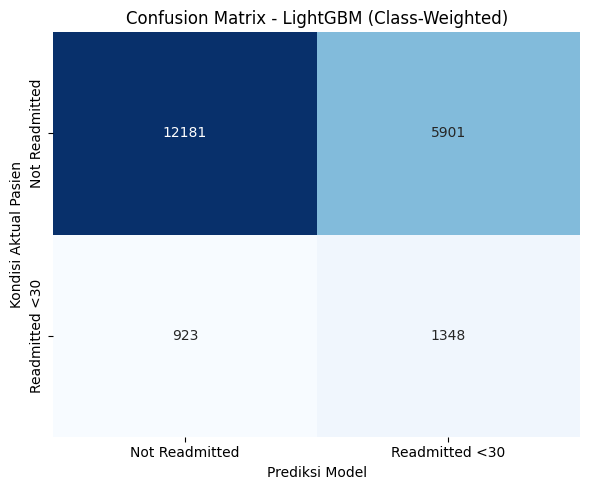

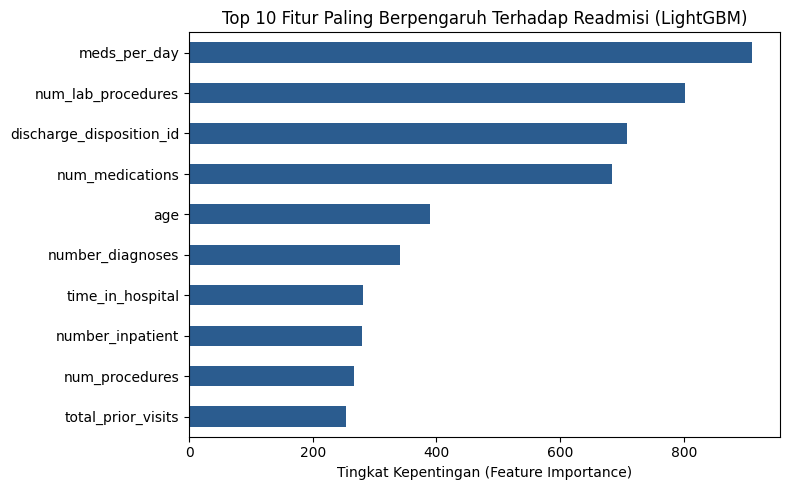

In [9]:
# ==============================================================================
# PIPELINES MACHINE LEARNING: DIABETES 130-US HOSPITALS READMISSION
# Target: Biner (<30 Hari vs Tidak/Lebih dari 30 Hari)
# Path: /content/diabetes_data/diabetic_data.csv
# ==============================================================================

# 1. Install & Import Library yang Dibutuhkan
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Cek & install LightGBM jika belum terpasang di Colab
try:
    import lightgbm as lgb
except ImportError:
    !pip install lightgbm
    import lightgbm as lgb

# ------------------------------------------------------------------------------
# 2. Load Dataset
# ------------------------------------------------------------------------------
DATA_PATH = "/content/diabetes_data/diabetic_data.csv"
print(f"[*] Membaca data dari: {DATA_PATH} ...")
df = pd.read_csv(DATA_PATH)
print(f"[*] Ukuran data awal: {df.shape[0]} baris, {df.shape[1]} kolom\n")

# ------------------------------------------------------------------------------
# 3. Data Cleaning & Feature Engineering
# ------------------------------------------------------------------------------
print("[*] Melakukan preprocessing data...")

# A. Ganti string '?' dengan NaN
df.replace('?', np.nan, inplace=True)

# B. Drop kolom ID (mencegah data leakage) dan kolom dengan missing value ekstrem
# - encounter_id & patient_nbr: ID unik (tidak relevan secara medis)
# - weight: ~97% missing
# - payer_code: ~40% missing & tidak relevan klinis
cols_to_drop = ['encounter_id', 'patient_nbr', 'weight', 'payer_code']
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# C. Tangani baris yang tidak valid (misal: gender 'Unknown/Invalid')
df = df[df['gender'] != 'Unknown/Invalid']

# D. Format Target Variabel (Binary Classification)
# 1 = Readmitted dini (<30 hari, prioritas klinis tinggi)
# 0 = Tidak readmit atau readmit >30 hari
df['target'] = df['readmitted'].apply(lambda x: 1 if x == '<30' else 0)
df.drop(columns=['readmitted'], inplace=True)

# E. Grouping ICD-9 Diagnosis Codes (diag_1, diag_2, diag_3) ke 9 Kategori Klinis
def categorize_icd9(val):
    if pd.isna(val):
        return 'Missing'
    val = str(val).strip()
    if val.startswith(('V', 'E')):
        return 'Other'
    try:
        code = float(val)
        if (390 <= code <= 459) or code == 785:
            return 'Circulatory'
        elif (460 <= code <= 519) or code == 786:
            return 'Respiratory'
        elif (520 <= code <= 579) or code == 787:
            return 'Digestive'
        elif int(code) == 250:
            return 'Diabetes'
        elif 800 <= code <= 999:
            return 'Injury'
        elif 710 <= code <= 739:
            return 'Musculoskeletal'
        elif (580 <= code <= 629) or code == 788:
            return 'Genitourinary'
        elif 140 <= code <= 239:
            return 'Neoplasms'
        else:
            return 'Other'
    except ValueError:
        return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].apply(categorize_icd9)

# F. Handling Medical Specialty (Kategori frekuensi rendah dikelompokkan ke 'Other')
top_specialties = df['medical_specialty'].value_counts().nlargest(10).index
df['medical_specialty'] = df['medical_specialty'].apply(
    lambda x: x if x in top_specialties else ('Missing' if pd.isna(x) else 'Other')
)

# G. Mapping Age (Ordinal Mapping nilai tengah)
age_map = {
    '[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
    '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95
}
df['age'] = df['age'].map(age_map)

# H. Feature Engineering Tambahan
# - Total kunjungan fasilitas kesehatan sebelumnya
df['total_prior_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']
# - Rasio jumlah obat terhadap lama rawat
df['meds_per_day'] = df['num_medications'] / np.maximum(df['time_in_hospital'], 1)

# I. Encoding Fitur Kategorikal lainnya (One-Hot Encoding)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Pastikan tidak ada NaN yang tersisa
df.fillna(0, inplace=True)
print(f"[*] Ukuran data setelah encoding: {df.shape[0]} baris, {df.shape[1]} fitur\n")

# ------------------------------------------------------------------------------
# 4. Train-Test Split (Anti-Leakage)
# ------------------------------------------------------------------------------
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"[*] Train set: {X_train.shape[0]} sampel | Test set: {X_test.shape[0]} sampel")
print(f"[*] Proporsi Kelas Positif (<30): Train={y_train.mean():.2%}, Test={y_test.mean():.2%}\n")

# Standarisasi fitur numerik (fit hanya pada train set)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------------------
# 5. Pelatihan Model & Benchmarking
# ------------------------------------------------------------------------------
models = {
    "Logistic Regression (Baseline)": {
        "model": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        "use_scaled": True
    },
    "Random Forest (Ensemble Bagging)": {
        "model": RandomForestClassifier(
            n_estimators=150, max_depth=12, class_weight='balanced_subsample',
            n_jobs=-1, random_state=42
        ),
        "use_scaled": False
    },
    "LightGBM (Ensemble Boosting)": {
        "model": lgb.LGBMClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6, num_leaves=31,
            scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), # Atasi imbalance
            n_jobs=-1, random_state=42, verbose=-1
        ),
        "use_scaled": False
    }
}

results = []

print("=" * 75)
print("MEMULAI TRAINING & EVALUASI MODEL")
print("=" * 75)

for name, cfg in models.items():
    print(f"\n[+] Melatih model: {name} ...")
    clf = cfg["model"]

    # Pilih dataset scaled untuk model linier
    X_tr = X_train_scaled if cfg["use_scaled"] else X_train
    X_te = X_test_scaled if cfg["use_scaled"] else X_test

    # Fit model
    clf.fit(X_tr, y_train)

    # Prediksi
    y_pred = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)[:, 1] if hasattr(clf, "predict_proba") else None

    # Hitung Metrik
    acc = accuracy_score(y_test, y_pred)
    b_acc = balanced_accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Balanced Acc": b_acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc
    })

    print(f"    - Accuracy:         {acc:.4f}")
    print(f"    - Balanced Acc:     {b_acc:.4f}")
    print(f"    - F1-Score:         {f1:.4f}")
    print(f"    - ROC-AUC:          {roc:.4f}")

# ------------------------------------------------------------------------------
# 6. Tabel Perbandingan Hasil Evaluasi
# ------------------------------------------------------------------------------
results_df = pd.DataFrame(results)
print("\n" + "=" * 75)
print("RINGKASAN PERBANDINGAN MODEL")
print("=" * 75)
print(results_df.to_string(index=False))

# ------------------------------------------------------------------------------
# 7. Visualisasi Confusion Matrix Model Terbaik (LightGBM)
# ------------------------------------------------------------------------------
best_model = models["LightGBM (Ensemble Boosting)"]["model"]
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Readmitted', 'Readmitted <30'],
            yticklabels=['Not Readmitted', 'Readmitted <30'])
plt.title('Confusion Matrix - LightGBM (Class-Weighted)', fontsize=12)
plt.xlabel('Prediksi Model', fontsize=10)
plt.ylabel('Kondisi Aktual Pasien', fontsize=10)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 8. Top 10 Feature Importance (LightGBM)
# ------------------------------------------------------------------------------
if hasattr(best_model, "feature_importances_"):
    feat_importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
    plt.figure(figsize=(8, 5))
    feat_importances.nlargest(10).plot(kind='barh', color='#2b5c8f')
    plt.title('Top 10 Fitur Paling Berpengaruh Terhadap Readmisi (LightGBM)', fontsize=12)
    plt.xlabel('Tingkat Kepentingan (Feature Importance)', fontsize=10)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()